# Análisis exploratorio de la Agenda Odontológica

**Estudiante:** Wilson Piter Martínez Solano  
**Proyecto:** Consultorio Odontológico Cristo Rey  
**Periodo del conjunto de análisis:** 10 de agosto–16 de noviembre de 2026 (371 citas)

> **Procedencia:** las 371 citas se presentan en una sola serie para todo el periodo indicado. De ellas, 51 provienen de la base fuente y 320 son sintéticas, identificadas con `es_sintetico`. Las sintéticas permiten ensayar el análisis, pero no representan actividad real ni deben usarse para afirmar tasas reales de ausentismo, consumo o demanda del consultorio.

El notebook sigue la secuencia trabajada en las prácticas de EDA: definir preguntas, limpiar y seleccionar datos, resumir distribuciones y formular conclusiones que no excedan la evidencia. No entrena un modelo predictivo.


## 1. Carga de datos y trazabilidad

Se carga la exportación CSV anonimizada. El indicador `es_sintetico` permite separar los registros de la fuente de los agregados para el ejercicio.


In [17]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATASET_NAME = "simulacion_2026-08-23_a_2026-11-16"
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.append(parent / "exportacion_bd" / DATASET_NAME / "csv")
    candidates.append(parent / "Agenda odontologica" / "exportacion_bd" / DATASET_NAME / "csv")
DATA_DIR = next((p for p in candidates if (p / "appointments.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("No se encontró el CSV. Abra el notebook desde la carpeta del proyecto.")

appointments = pd.read_csv(DATA_DIR / "appointments.csv")
transactions = pd.read_csv(DATA_DIR / "inventory_transactions.csv")
appointments["es_sintetico"] = appointments["es_sintetico"].astype(str).str.lower().eq("true")
transactions["es_sintetico"] = transactions["es_sintetico"].astype(str).str.lower().eq("true")
appointments["appointment_date"] = pd.to_datetime(appointments["appointment_date"], errors="coerce")
appointments["created_at"] = pd.to_datetime(appointments["created_at"], errors="coerce")
transactions["fecha"] = pd.to_datetime(transactions["fecha"], errors="coerce")

print("CSV:", DATA_DIR)
print("Citas:", len(appointments))
print("Fuente:", int((~appointments["es_sintetico"]).sum()))
print("Sintéticas:", int(appointments["es_sintetico"].sum()))


CSV: c:\Users\user\Documents\AntigravityTaller\Agenda odontologica\exportacion_bd\simulacion_2026-08-23_a_2026-11-16\csv
Citas: 371
Fuente: 51
Sintéticas: 320


## 2. Calidad y cobertura

Se revisan fechas, valores faltantes, duplicados, domingos y estados. Las validaciones detectan problemas del archivo, pero no prueban que los registros de la fuente correspondan a atenciones reales.


In [18]:
source = appointments.loc[~appointments["es_sintetico"]].copy()
synthetic = appointments.loc[appointments["es_sintetico"]].copy()

print("Rango completo:", appointments["appointment_date"].min(), "a", appointments["appointment_date"].max())
print("Duplicados exactos:", int(appointments.duplicated().sum()))
print("Turnos duplicados por fecha/hora:", int(appointments.duplicated(["appointment_date", "appointment_time"]).sum()))
print("Citas en domingo:", int((appointments["appointment_date"].dt.dayofweek == 6).sum()))
appointment_datetime = pd.to_datetime(
    appointments["appointment_date"].dt.strftime("%Y-%m-%d") + " " + appointments["appointment_time"],
    errors="coerce",
)
late_source_timestamps = (
    (~appointments["es_sintetico"])
    & (appointments["created_at"] > appointment_datetime)
)
print("Marcas created_at posteriores a la cita en la fuente:", int(late_source_timestamps.sum()))
print("\nEstados por procedencia:")
print(appointments.groupby(["es_sintetico", "status"]).size().unstack(fill_value=0))
print("\nValores faltantes relevantes:")
print(appointments[["appointment_date", "appointment_time", "status", "patient_id"]].isna().sum())


Rango completo: 2026-08-10 00:00:00 a 2026-11-16 00:00:00
Duplicados exactos: 0
Turnos duplicados por fecha/hora: 0
Citas en domingo: 0
Marcas created_at posteriores a la cita en la fuente: 51

Estados por procedencia:
status        Atendida  Ausente  Cancelada  Completada  En Espera  Programada
es_sintetico                                                                 
False                0        0          0          47          1           3
True               266       33         21           0          0           0

Valores faltantes relevantes:
appointment_date    0
appointment_time    0
status              0
patient_id          0
dtype: int64


## 3. Pregunta: ¿cuántas citas hubo por mes en la serie completa?

Se suman las citas de la base de análisis en una sola serie mensual. Como parte de los registros es sintética, estos totales describen el conjunto de análisis y no la demanda histórica real.


,Citas totales
month,
2026-08,83
2026-09,120
2026-10,111
2026-11,57


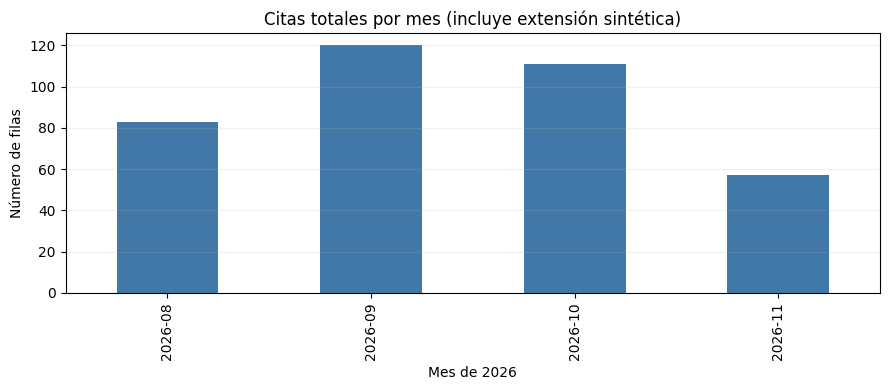

In [19]:
appointments["month"] = appointments["appointment_date"].dt.to_period("M").astype(str)
monthly = appointments.groupby("month").size()
display(monthly.to_frame("Citas totales"))

ax = monthly.plot(kind="bar", figsize=(9, 4), color="#4278a8")
ax.set_title("Citas totales por mes (incluye extensión sintética)")
ax.set_xlabel("Mes de 2026")
ax.set_ylabel("Número de filas")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


## 4. Pregunta: ¿qué estados aparecen en las citas simuladas?

Los estados de las citas de la fuente (`Completada`, `En Espera`, `Programada`) no se deben mezclar sin normalización con los simulados (`Atendida`, `Ausente`, `Cancelada`). La distribución siguiente solo describe la generación artificial.


,citas simuladas
status,
Atendida,266
Ausente,33
Cancelada,21


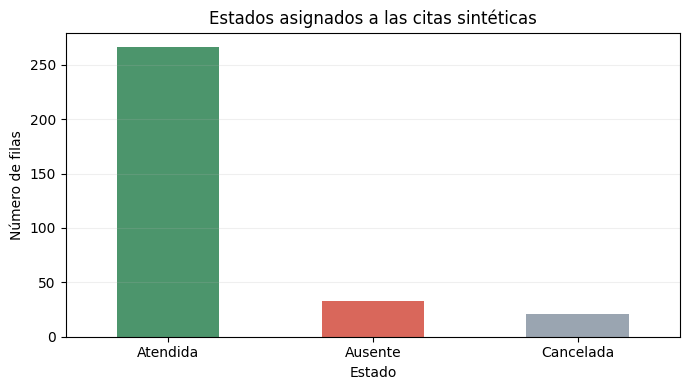

In [20]:
status_counts = synthetic["status"].value_counts().reindex(
    ["Atendida", "Ausente", "Cancelada"], fill_value=0
)
display(status_counts.to_frame("citas simuladas"))
ax = status_counts.plot(kind="bar", figsize=(7, 4), color=["#4c956c", "#d9675b", "#9aa5b1"])
ax.set_title("Estados asignados a las citas sintéticas")
ax.set_xlabel("Estado")
ax.set_ylabel("Número de filas")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


## 5. Pregunta: ¿qué categorías de tratamiento y movimientos de inventario se registran?

El catálogo contiene tratamientos existentes, pero las citas simuladas se asignaron artificialmente. De igual modo, las entradas, salidas y ajustes simulados no equivalen a compras o consumo observados.


,asociaciones simuladas
categoria,
Preventiva,105
Restauración,63
Endodoncia,38
Implantología,22
Ortodoncia,18
Prótesis,17
Periodoncia,16
General,15
Cirugía,13


,movimientos simulados
tipo,
ENTRADA,12
SALIDA,169
AJUSTE,3


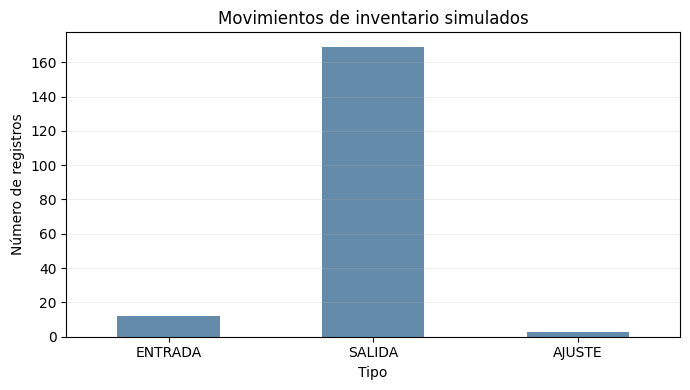

In [21]:
links = pd.read_csv(DATA_DIR / "appointment_treatments.csv")
treatments = pd.read_csv(DATA_DIR / "treatments.csv")
links["es_sintetico"] = links["es_sintetico"].astype(str).str.lower().eq("true")
synthetic_links = links.loc[links["es_sintetico"]]
category_counts = (
    synthetic_links.merge(treatments[["id", "categoria"]], left_on="treatment_id", right_on="id")
    .groupby("categoria").size().sort_values(ascending=False)
)
display(category_counts.to_frame("asociaciones simuladas"))

synthetic_transactions = transactions.loc[transactions["es_sintetico"]]
movement_counts = synthetic_transactions["tipo"].value_counts().reindex(
    ["ENTRADA", "SALIDA", "AJUSTE"], fill_value=0
)
display(movement_counts.to_frame("movimientos simulados"))
ax = movement_counts.plot(kind="bar", figsize=(7, 4), color="#648caa")
ax.set_title("Movimientos de inventario simulados")
ax.set_xlabel("Tipo")
ax.set_ylabel("Número de registros")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


## 6. Resumen del periodo completo

Se suman las citas de todo el conjunto, desde el inicio de los registros disponibles hasta el 16 de noviembre. El promedio combinado usa los días de lunes a sábado; incluye citas sintéticas y describe la copia de análisis, no la actividad real del consultorio.


In [22]:
period_start = appointments["appointment_date"].min().normalize()
period_end = appointments["appointment_date"].max().normalize()
open_days = pd.date_range(period_start, period_end, freq="D")
open_days = open_days[open_days.dayofweek != 6]
combined_average = len(appointments) / len(open_days)
print("Periodo completo:", period_start.date(), "a", period_end.date())
print("Citas totales del conjunto:", len(appointments))
print("Días abiertos considerados (lunes a sábado):", len(open_days))
print("Promedio combinado por día abierto:", round(combined_average, 2))
print("Este promedio incluye citas sintéticas; no es una tasa real del consultorio.")
source_days = pd.date_range(source["appointment_date"].min(), source["appointment_date"].max(), freq="D")
source_days = source_days[source_days.dayofweek != 6]
print("Citas registradas en la fuente por día abierto:", round(len(source) / len(source_days), 2))


Periodo completo: 2026-08-10 a 2026-11-16
Citas totales del conjunto: 371
Días abiertos considerados (lunes a sábado): 85
Promedio combinado por día abierto: 4.36
Este promedio incluye citas sintéticas; no es una tasa real del consultorio.
Citas registradas en la fuente por día abierto: 4.25


## 7. Conclusiones y límites

1. La copia de análisis reúne 371 citas del 10 de agosto al 16 de noviembre; su promedio combinado incluye citas sintéticas, por lo que no representa la demanda real. Solo las 51 filas con `es_sintetico=False` provienen de la base original y su veracidad operativa tampoco fue verificada independientemente.
2. Las 320 citas añadidas, las ausencias y los movimientos de inventario son datos artificiales. No permiten estimar demanda real, ausentismo, gasto ni eficacia de un modelo.
3. La fuente presenta estados históricos pendientes y marcas `created_at` posteriores a la cita; esas variables requieren validación antes de cualquier modelo.
4. No se debe entrenar un clasificador de inasistencia con este conjunto como si las etiquetas fueran reales. La siguiente etapa válida es recopilar registros autorizados, con definiciones consistentes y fechas fiables.


## 8. Aplicación de aprendizaje supervisado: predicción de ausentismo

Se comparan una **Regresión Logística** y un **Random Forest** para clasificar una cita sintética como `Atendida` o `Ausente`. La variable objetivo es `ausente = 1` y `atendida = 0`.

Las variables incluyen fecha, hora, tratamiento, edad, sexo y el historial previo del paciente. El historial se calcula solo con citas anteriores para evitar fuga de datos. Las citas canceladas se excluyen del experimento.

Los registros sintéticos permiten ensayar el método, pero no representan el ausentismo real del consultorio. Los resultados deben presentarse como una prueba académica y no como una herramienta clínica operativa.


In [23]:
from pathlib import Path
import runpy

script = Path.cwd() / "entrenar_prediccion_ausentismo.py"
if not script.is_file():
    script = Path.cwd().parent / "Proyecto_Ciencia_de_Datos" / "entrenar_prediccion_ausentismo.py"

runpy.run_path(str(script), run_name="__main__")


Citas sintéticas utilizadas: 299
Entrenamiento: 239 Prueba: 60
Fechas de prueba: 2026-10-30 08:30:00 a 2026-11-16 21:30:00
regresion_logistica
{'accuracy': 0.5833333333333334, 'balanced_accuracy': 0.47, 'precision': 0.14285714285714285, 'recall': 0.3, 'f1': 0.1935483870967742, 'roc_auc': 0.46799999999999997, 'confusion_matrix': [[32, 18], [7, 3]]}
random_forest
{'accuracy': 0.8333333333333334, 'balanced_accuracy': 0.5, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.494, 'confusion_matrix': [[50, 0], [10, 0]]}


{'__name__': '__main__',
 '__doc__': None,
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'c:\\Users\\user\\Documents\\AntigravityTaller\\Agenda odontologica\\Proyecto_Ciencia_de_Datos\\entrenar_prediccion_ausentismo.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, exceptions, and other objects.\n\nNoteworthy: None is the `nil' object; Ellipsis represents `...' in slices.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__import__': <function __import__>,
  'abs': <function abs(x, /)>,
  'all': <function all(iterable, /)>,
  'any': <function any(iterable, /)>,
  'ascii': <function ascii(obj, /)>,
  'bin': <function bin(number, /)>,
  'breakpoint': <function breakpoint>,
  'callable': <function callable(obj, /)>,
  'chr':

## 9. Interpretación de los resultados y límites

Los modelos generan estos artefactos en `Proyecto_Ciencia_de_Datos/modelos/`:

- `regresion_logistica.joblib`: pipeline entrenado de Regresión Logística.
- `random_forest.joblib`: pipeline entrenado de Random Forest.
- `metricas_modelos.csv` y `metricas_modelos.json`: resultados de evaluación.
- `predicciones_prueba.csv`: predicciones temporales sobre las últimas citas del conjunto.

En el primer experimento se reservaron 60 citas recientes para prueba. La Regresión Logística obtuvo recall de ausencias de 0.30 y el Random Forest no detectó ausencias. Por esta razón, el modelo todavía no debe utilizarse para decisiones reales.

Es necesario mejorar el conjunto con citas reales verificadas, una definición consistente de ausencia, validación temporal amplia y una estrategia para corregir el desbalance de clases. El resultado actual demuestra el flujo del aprendizaje supervisado, no la eficacia real del consultorio.


## 10. Formulario para una cita nueva

El siguiente formulario permite seleccionar las características de una cita futura y obtener una estimación con la Regresión Logística entrenada.

La salida es demostrativa y utiliza datos sintéticos. No debe interpretarse como una decisión clínica o como una garantía operativa.


In [24]:
from datetime import date
from pathlib import Path

import ipywidgets as widgets
import joblib
import pandas as pd
from IPython.display import clear_output, display

project_candidates = [Path.cwd(), *Path.cwd().parents]
project_candidates += [path / "Agenda odontologica" / "Proyecto_Ciencia_de_Datos" for path in [Path.cwd(), *Path.cwd().parents]]
PROJECT_DIR = next((path for path in project_candidates if (path / "modelos" / "regresion_logistica.joblib").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("No se encontró el modelo. Ejecute primero la sección 8 para entrenarlo.")

DATA_DIR = PROJECT_DIR.parent / "exportacion_bd" / "simulacion_2026-08-23_a_2026-11-16" / "csv"
modelo_ausentismo = joblib.load(PROJECT_DIR / "modelos" / "regresion_logistica.joblib")
catalogo_tratamientos = pd.read_csv(DATA_DIR / "treatments.csv")
tratamientos_activos = catalogo_tratamientos.loc[
    catalogo_tratamientos["eliminado"].eq(0) & catalogo_tratamientos["activo"].eq(1)
].copy()
nombres_tratamientos = sorted(tratamientos_activos["nombre"].dropna().unique())
if not nombres_tratamientos:
    raise ValueError("El catálogo no contiene tratamientos activos para mostrar.")

estilo_campos = {"description_width": "180px"}
ancho_campo = widgets.Layout(width="100%")

fecha_cita = widgets.DatePicker(description="Fecha de la cita:", value=date.today(), style=estilo_campos, layout=ancho_campo)
hora_cita = widgets.SelectionSlider(
    description="Hora de la cita:",
    options=["07:30", "08:30", "09:30", "10:30", "11:30", "12:30", "14:30", "15:30", "16:30", "17:30", "18:30", "19:30", "20:30", "21:30"],
    value="09:30",
    style=estilo_campos,
    layout=ancho_campo,
)
tratamiento_cita = widgets.Dropdown(description="Tratamiento odontológico:", options=nombres_tratamientos, style=estilo_campos, layout=ancho_campo)
sexo_paciente = widgets.Dropdown(description="Sexo del paciente:", options=["M", "F", "Otro"], value="M", style=estilo_campos, layout=ancho_campo)
edad_paciente = widgets.BoundedIntText(description="Edad del paciente (años):", min=1, max=120, value=30, style=estilo_campos, layout=ancho_campo)
citas_previas = widgets.BoundedIntText(description="Cantidad de citas previas:", min=0, max=500, value=0, style=estilo_campos, layout=ancho_campo)
ausencias_previas = widgets.BoundedIntText(description="Ausencias previas:", min=0, max=500, value=0, style=estilo_campos, layout=ancho_campo)
atenciones_previas = widgets.BoundedIntText(description="Atenciones previas:", min=0, max=500, value=0, style=estilo_campos, layout=ancho_campo)
dias_desde_ultima = widgets.BoundedIntText(description="Días desde la cita anterior:", min=0, max=3650, value=0, style=estilo_campos, layout=ancho_campo)
costo_cita = widgets.BoundedFloatText(description="Costo (0 usa costo base):", min=0, max=100000, value=0, step=10, style=estilo_campos, layout=ancho_campo)
salida_prediccion = widgets.Output()
boton_predecir = widgets.Button(description="Predecir resultado", button_style="primary", icon="calculator", layout=widgets.Layout(width="auto"))

def predecir_cita(_):
    if fecha_cita.value is None:
        with salida_prediccion:
            clear_output()
            print("Seleccione una fecha para la cita.")
        return

    tratamiento_seleccionado = tratamientos_activos.loc[
        tratamientos_activos["nombre"].eq(tratamiento_cita.value)
    ].iloc[0]
    hora, minuto = map(int, hora_cita.value.split(":"))
    fecha_hora = pd.Timestamp(fecha_cita.value).replace(hour=hora, minute=minuto)
    total_previas = citas_previas.value
    tasa_ausencia = ausencias_previas.value / total_previas if total_previas else 0
    costo = costo_cita.value if costo_cita.value > 0 else float(tratamiento_seleccionado["costo_base"])

    entrada = pd.DataFrame([{
        "dia_semana": fecha_hora.dayofweek,
        "mes": fecha_hora.month,
        "hora": hora + minuto / 60,
        "edad": edad_paciente.value,
        "sexo": sexo_paciente.value,
        "treatment": tratamiento_cita.value,
        "categorias": str(tratamiento_seleccionado["categoria"]),
        "costo": costo,
        "citas_previas": total_previas,
        "ausencias_previas": ausencias_previas.value,
        "atenciones_previas": atenciones_previas.value,
        "tasa_ausencia_previa": tasa_ausencia,
        "dias_desde_cita_anterior": dias_desde_ultima.value,
    }])
    probabilidad_ausencia = float(modelo_ausentismo.predict_proba(entrada)[0, 1])
    resultado = "AUSENTE" if probabilidad_ausencia >= 0.5 else "ATENDIDA"

    with salida_prediccion:
        clear_output()
        display(widgets.HTML(
            f"<h3>Predicción: {resultado}</h3>"
            f"<p>Probabilidad de ausencia: <b>{probabilidad_ausencia:.1%}</b></p>"
            f"<p>Probabilidad de atención: <b>{1 - probabilidad_ausencia:.1%}</b></p>"
        ))

boton_predecir.on_click(predecir_cita)
display(widgets.VBox([
    widgets.HTML("<h2>Formulario de predicción de ausentismo</h2>"),
    fecha_cita, hora_cita, tratamiento_cita, sexo_paciente, edad_paciente,
    citas_previas, ausencias_previas, atenciones_previas, dias_desde_ultima,
    costo_cita, boton_predecir, salida_prediccion,
], layout=widgets.Layout(width="100%")))
